# CP3 — Task 3: Evaluasi Eksperimen/Track (Hybrid Recommendation)

**Proyek:** Amazon Reviews 2023 – Musical Instruments (Track G)

## Tujuan
Mengevaluasi pendekatan eksperimen yang menggabungkan:
- Item-Based Collaborative Filtering (Item-CF)
- TF-IDF Content-Based Filtering (CBF)

Dua strategi hybrid yang dibandingkan:
1. **Weighted Score Fusion** — menggabungkan skor Item-CF dan CBF setelah normalisasi per pengguna.
2. **Reciprocal Rank Fusion (RRF)** — menggabungkan posisi ranking dari kedua model.

Evaluasi menggunakan protokol yang sama dengan Task 1 dan Task 2: **validation warm**, candidate universe resmi, seen-item exclusion, relevansi rating ≥ 4, serta Recall@10 dan NDCG@10.

> Penting: seluruh pemilihan konfigurasi dilakukan pada validation warm. Notebook ini tidak menggunakan final test.

## 1. Import library dan inisialisasi proyek

Jalankan notebook dari **folder utama repository** yang berisi `src/`, folder `MAIN DATA-...`, dan `SUPPORTING_DATA-...`.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc
import hashlib
import joblib
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "src" / "data.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Folder repository tidak ditemukan. Jalankan notebook dari folder proyek "
        "yang berisi src/data.py dan folder dataset."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_project_data
from src.evaluation import build_relevant_items, evaluate_ranking
from src.recommenders import (
    fit_popularity,
    fit_item_cf,
    fit_tfidf_cbf,
    recommend_from_model,
    recommend_popularity,
    _prepare_matrices,
)
from src.fusion import weighted_score_fusion, reciprocal_rank_fusion

K = 10
TOP_N = 200
FUSION_TOP_N = K  # Evaluasi hanya membutuhkan Top-10; input komponen tetap Top-200.
POSITIVE_THRESHOLD = 4
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "task3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Output dir  :", OUTPUT_DIR)

C:\Users\Rache\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Project root: d:\Hybrid-Fusion-Strategies-for-Collaborative-and-Content-Based-Recommender-Systems\Hybrid-Fusion-Strategies-for-Collaborative-and-Content-Based-Recommender-Systems
Output dir  : d:\Hybrid-Fusion-Strategies-for-Collaborative-and-Content-Based-Recommender-Systems\Hybrid-Fusion-Strategies-for-Collaborative-and-Content-Based-Recommender-Systems\outputs\task3


## 2. Memuat data dan protokol evaluasi

Data dimuat melalui fungsi resmi `load_project_data`, sama seperti notebook hybrid sebelumnya. Ground truth dibentuk dari validation warm dengan rating minimal 4.

In [2]:
data = load_project_data(PROJECT_ROOT)

train = data.train.copy()
items = data.items.copy()
candidates = list(dict.fromkeys(str(x) for x in data.candidates))
eval_users = list(dict.fromkeys(str(x) for x in data.evaluable_users))
validation = data.validation_warm.copy()

train["user_id"] = train["user_id"].astype(str)
train["item_id"] = train["item_id"].astype(str)
train["rating"] = pd.to_numeric(train["rating"], errors="raise")
items["item_id"] = items["item_id"].astype(str)
validation["user_id"] = validation["user_id"].astype(str)
validation["item_id"] = validation["item_id"].astype(str)
validation["rating"] = pd.to_numeric(validation["rating"], errors="raise")

candidate_set = set(candidates)
eval_user_set = set(eval_users)
seen_by_user = {
    uid: set(group["item_id"])
    for uid, group in train.groupby("user_id", sort=False)
}
relevant = build_relevant_items(
    validation,
    eval_users,
    positive_threshold=POSITIVE_THRESHOLD,
)

print(f"Training interactions : {len(train):,}")
print(f"Validation warm      : {len(validation):,}")
print(f"Candidate universe   : {len(candidate_set):,}")
print(f"Evaluable users      : {len(eval_users):,}")
print(f"Users with target    : {len(relevant):,}")
print(f"Top-N component      : {TOP_N}")
print(f"Evaluation metric    : Recall@{K} dan NDCG@{K}")

assert len(candidate_set) == len(candidates), "Candidate list memiliki duplikasi."
assert eval_user_set.issubset(set(train["user_id"])), "Ada evaluable user yang tidak ada di training."
assert candidate_set.issubset(set(train["item_id"])), "Candidate item tidak seluruhnya ada di training."

Training interactions : 427,957
Validation warm      : 27,537
Candidate universe   : 22,753
Evaluable users      : 11,659
Users with target    : 11,659
Top-N component      : 200
Evaluation metric    : Recall@10 dan NDCG@10


## 3. Membentuk baseline dan ranking komponen

Item-CF dan TF-IDF CBF tetap dibentuk dari seluruh data training dan candidate universe resmi. Ranking komponen tetap Top-200. Untuk mempercepat pengulangan, hasil rekomendasi tiap baseline disimpan ke cache lokal (`outputs/task3/cache/`) dan digunakan kembali jika fingerprint data serta parameter sama.

TF-IDF similarity dihitung per blok dengan matriks sparse dan buffer yang sudah dialokasikan. `CHUNK_SIZE=16` adalah titik awal; turunkan ke 8 ou 4 jika RAM terbatas. Fusion hanya menyimpan Top-10 karena metrik eksperimen adalah Recall@10 dan NDCG@10.


In [3]:
# Cache key: berubah otomatis jika data inti atau parameter eksperimen berubah.
CACHE_DIR = OUTPUT_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

fingerprint = hashlib.sha1()
for frame, columns in [
    (train, ["user_id", "item_id", "rating"]),
    (items, ["item_id", "content_text_basic"]),
]:
    hashed = pd.util.hash_pandas_object(frame[columns], index=False)
    fingerprint.update(hashed.values.tobytes())
fingerprint.update("|".join(candidates).encode("utf-8"))
fingerprint.update("|".join(eval_users).encode("utf-8"))
fingerprint.update(f"|thr={POSITIVE_THRESHOLD}|topk=100|topn={TOP_N}".encode("utf-8"))
CACHE_KEY = fingerprint.hexdigest()[:16]
print("Cache key:", CACHE_KEY)

def cached_result(name, build_function):
    path = CACHE_DIR / f"{name}_{CACHE_KEY}.joblib"
    if path.exists():
        print(f"[CACHE HIT] {name}")
        return joblib.load(path)
    print(f"[BUILD] {name} ...")
    value = build_function()
    joblib.dump(value, path, compress=1)
    print(f"[SAVED] {path.name}")
    return value

# 1) Popularity baseline
popularity_model = fit_popularity(train, positive_threshold=POSITIVE_THRESHOLD)
pop_recs = cached_result(
    "popularity_recommendations",
    lambda: recommend_popularity(
        eval_users, candidates, popularity_model, seen_by_user, top_n=TOP_N
    ),
)

# 2) Item-CF: model dibuat hanya jika hasil rekomendasinya belum ada di cache.
def build_item_cf_recommendations():
    model = fit_item_cf(
        train, candidates, top_k=100, positive_threshold=POSITIVE_THRESHOLD
    )
    recs = recommend_from_model(
        model, eval_users, candidates, popularity_model, top_n=TOP_N
    )
    del model
    gc.collect()
    return recs

cf_recs = cached_result("item_cf_recommendations", build_item_cf_recommendations)

# 3) TF-IDF CBF: cache rekomendasi menghindari pengulangan proses TF-IDF yang berat.
def build_tfidf_cbf_recommendations():
    assert "content_text_basic" in items.columns, (
        "Kolom content_text_basic tidak ditemukan pada metadata item."
    )

    user_ids, item_ids, user_index, item_index, interactions, seen = _prepare_matrices(
        train, candidates, POSITIVE_THRESHOLD
    )

    metadata = items[["item_id", "content_text_basic"]].copy()
    metadata["item_id"] = metadata["item_id"].astype(str)
    text_by_id = metadata.set_index("item_id")["content_text_basic"].fillna("").astype(str)
    documents = [text_by_id.get(item_id, "") for item_id in item_ids]
    del metadata, text_by_id

    vectorizer = TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.8,
        max_features=100_000,
        sublinear_tf=True,
        dtype=np.float32,
    )
    item_vectors = vectorizer.fit_transform(documents).tocsr()
    del documents
    gc.collect()

    TOP_K_SIMILARITY = 100
    CHUNK_SIZE = 16  # Jika RAM terbatas: 8 atau 4.
    n_items = item_vectors.shape[0]

    # Pre-allocation menghindari banyak list sementara dan operasi concatenate besar.
    max_edges = n_items * TOP_K_SIMILARITY
    graph_rows = np.empty(max_edges, dtype=np.int32)
    graph_cols = np.empty(max_edges, dtype=np.int32)
    graph_values = np.empty(max_edges, dtype=np.float32)
    cursor = 0

    for start in range(0, n_items, CHUNK_SIZE):
        stop = min(start + CHUNK_SIZE, n_items)
        block_similarity = (item_vectors[start:stop] @ item_vectors.T).tocsr()
        block_similarity.eliminate_zeros()

        for local_row in range(stop - start):
            global_row = start + local_row
            left, right = block_similarity.indptr[local_row:local_row + 2]
            row_cols = block_similarity.indices[left:right]
            row_values = block_similarity.data[left:right]

            # Sama seperti implementasi graph Top-K: buang self-similarity.
            valid = row_cols != global_row
            row_cols = row_cols[valid]
            row_values = row_values[valid]

            if len(row_values) > TOP_K_SIMILARITY:
                keep = np.argpartition(row_values, -TOP_K_SIMILARITY)[-TOP_K_SIMILARITY:]
                row_cols = row_cols[keep]
                row_values = row_values[keep]

            count = len(row_cols)
            if count:
                graph_rows[cursor:cursor + count] = global_row
                graph_cols[cursor:cursor + count] = row_cols
                graph_values[cursor:cursor + count] = row_values
                cursor += count

        del block_similarity
        if (start // CHUNK_SIZE) % 100 == 0:
            print(f"TF-IDF similarity: {stop:,}/{n_items:,} item selesai")
        gc.collect()

    similarity_graph = sparse.csr_matrix(
        (graph_values[:cursor], (graph_rows[:cursor], graph_cols[:cursor])),
        shape=(n_items, n_items),
        dtype=np.float32,
    )

    model = {
        "user_ids": user_ids,
        "item_ids": item_ids,
        "user_index": user_index,
        "item_index": item_index,
        "interactions": interactions,
        "seen": seen,
        "similarity": similarity_graph,
        "vectorizer": vectorizer,
    }
    recs = recommend_from_model(
        model, eval_users, candidates, popularity_model, top_n=TOP_N
    )

    del model, item_vectors, similarity_graph
    del graph_rows, graph_cols, graph_values
    gc.collect()
    return recs

cbf_recs = cached_result("tfidf_cbf_recommendations", build_tfidf_cbf_recommendations)

assert set(cf_recs) == eval_user_set
assert set(cbf_recs) == eval_user_set
assert set(pop_recs) == eval_user_set

component_results = pd.DataFrame([
    {"Model": "Popularity", **evaluate_ranking(pop_recs, relevant, eval_users, k=K)},
    {"Model": "Item-CF", **evaluate_ranking(cf_recs, relevant, eval_users, k=K)},
    {"Model": "TF-IDF CBF", **evaluate_ranking(cbf_recs, relevant, eval_users, k=K)},
]).set_index("Model")[["recall@10", "ndcg@10"]]

display(component_results)


Cache key: 13454c5090f84bab
[BUILD] popularity_recommendations ...
[SAVED] popularity_recommendations_13454c5090f84bab.joblib
[BUILD] item_cf_recommendations ...


d:\Anacondaa\Lib\site-packages\scipy\sparse\_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


[SAVED] item_cf_recommendations_13454c5090f84bab.joblib
[BUILD] tfidf_cbf_recommendations ...
TF-IDF similarity: 16/22,753 item selesai
TF-IDF similarity: 1,616/22,753 item selesai
TF-IDF similarity: 3,216/22,753 item selesai
TF-IDF similarity: 4,816/22,753 item selesai
TF-IDF similarity: 6,416/22,753 item selesai
TF-IDF similarity: 8,016/22,753 item selesai
TF-IDF similarity: 9,616/22,753 item selesai
TF-IDF similarity: 11,216/22,753 item selesai
TF-IDF similarity: 12,816/22,753 item selesai
TF-IDF similarity: 14,416/22,753 item selesai
TF-IDF similarity: 16,016/22,753 item selesai
TF-IDF similarity: 17,616/22,753 item selesai
TF-IDF similarity: 19,216/22,753 item selesai
TF-IDF similarity: 20,816/22,753 item selesai
TF-IDF similarity: 22,416/22,753 item selesai
[SAVED] tfidf_cbf_recommendations_13454c5090f84bab.joblib


,recall@10,ndcg@10
Model,,
Popularity,0.013499,0.009222
Item-CF,0.005800,0.003323
TF-IDF CBF,0.012148,0.007491


## 4. Eksperimen A — Weighted Score Fusion

Skor komponen dinormalisasi per pengguna oleh fungsi `weighted_score_fusion`, kemudian digabungkan:

\[
HybridScore = \alpha \times ItemCF + (1-\alpha) \times CBF
\]

Nilai bobot Item-CF diuji dari 0.0 sampai 1.0 dengan interval 0.1. Bobot terbaik dipilih berdasarkan **NDCG@10 tertinggi**, lalu Recall@10 sebagai pemecah seri. Seluruh pemilihan hanya menggunakan validation warm.

In [4]:
weighted_rows = []
weighted_runs = {}

for cf_weight in [i / 10 for i in range(11)]:
    recs = weighted_score_fusion(
        cf_recs,
        cbf_recs,
        eval_users,
        cf_weight=cf_weight,
        top_n=FUSION_TOP_N,
    )
    metrics = evaluate_ranking(recs, relevant, eval_users, k=K)
    weighted_runs[cf_weight] = recs
    weighted_rows.append({
        "bobot_item_cf": cf_weight,
        "bobot_tfidf_cbf": round(1 - cf_weight, 1),
        **metrics,
    })

weighted_results = (
    pd.DataFrame(weighted_rows)
    .sort_values(["ndcg@10", "recall@10"], ascending=False)
    .reset_index(drop=True)
)

display(weighted_results)
best_weight_row = weighted_results.iloc[0]
best_cf_weight = float(best_weight_row["bobot_item_cf"])
best_weighted_recs = weighted_runs[best_cf_weight]

print(f"Bobot terbaik Item-CF : {best_cf_weight:.1f}")
print(f"Bobot terbaik TF-IDF  : {1 - best_cf_weight:.1f}")

,bobot_item_cf,bobot_tfidf_cbf,users_evaluated,recall@10,ndcg@10
0,0.3,0.7,11659,0.012820,0.007930
1,0.2,0.8,11659,0.012455,0.007774
2,0.4,0.6,11659,0.012401,0.007726
3,0.1,0.9,11659,0.012670,0.007703
4,0.0,1.0,11659,0.012148,0.007491
5,0.5,0.5,11659,0.012049,0.007406
6,0.6,0.4,11659,0.010702,0.006239
7,0.7,0.3,11659,0.008598,0.005006
8,0.8,0.2,11659,0.006808,0.004026
9,0.9,0.1,11659,0.006168,0.003599


Bobot terbaik Item-CF : 0.3
Bobot terbaik TF-IDF  : 0.7


## 5. Eksperimen B — Reciprocal Rank Fusion (RRF)

RRF menggabungkan ranking Item-CF dan CBF berdasarkan posisi item, bukan menjumlahkan skor mentah. Konfigurasi `rrf_k` diuji pada 10, 20, 40, 60, 80, dan 100.

Konfigurasi terbaik juga dipilih berdasarkan **NDCG@10 tertinggi**, kemudian Recall@10 sebagai pemecah seri.

In [5]:
rrf_rows = []
rrf_runs = {}

for rrf_k in [10, 20, 40, 60, 80, 100]:
    recs = reciprocal_rank_fusion(
        cf_recs,
        cbf_recs,
        eval_users,
        rrf_k=rrf_k,
        top_n=FUSION_TOP_N,
    )
    metrics = evaluate_ranking(recs, relevant, eval_users, k=K)
    rrf_runs[rrf_k] = recs
    rrf_rows.append({
        "rrf_k": rrf_k,
        **metrics,
    })

rrf_results = (
    pd.DataFrame(rrf_rows)
    .sort_values(["ndcg@10", "recall@10"], ascending=False)
    .reset_index(drop=True)
)

display(rrf_results)
best_rrf_row = rrf_results.iloc[0]
best_rrf_k = int(best_rrf_row["rrf_k"])
best_rrf_recs = rrf_runs[best_rrf_k]

print(f"Konfigurasi RRF terbaik: k = {best_rrf_k}")

,rrf_k,users_evaluated,recall@10,ndcg@10
0,100,11659,0.014198,0.009086
1,60,11659,0.013565,0.008750
2,80,11659,0.013259,0.008661
3,40,11659,0.012633,0.008291
4,20,11659,0.012407,0.007841
5,10,11659,0.011538,0.007215


Konfigurasi RRF terbaik: k = 100


## 6. Perbandingan hasil eksperimen

Tabel ini membandingkan baseline komponen dengan konfigurasi terbaik dari masing-masing strategi hybrid. Nilai yang ditampilkan adalah hasil validation warm.

In [6]:
best_weighted_metrics = evaluate_ranking(
    best_weighted_recs, relevant, eval_users, k=K
)
best_rrf_metrics = evaluate_ranking(
    best_rrf_recs, relevant, eval_users, k=K
)

comparison = pd.DataFrame([
    {"Model": "Popularity", **evaluate_ranking(pop_recs, relevant, eval_users, k=K)},
    {"Model": "Item-CF", **evaluate_ranking(cf_recs, relevant, eval_users, k=K)},
    {"Model": "TF-IDF CBF", **evaluate_ranking(cbf_recs, relevant, eval_users, k=K)},
    {"Model": f"Weighted Score (CF={best_cf_weight:.1f})", **best_weighted_metrics},
    {"Model": f"RRF (k={best_rrf_k})", **best_rrf_metrics},
]).set_index("Model")[["recall@10", "ndcg@10"]]

display(comparison.sort_values("ndcg@10", ascending=False))

,recall@10,ndcg@10
Model,,
Popularity,0.013499,0.009222
RRF (k=100),0.014198,0.009086
Weighted Score (CF=0.3),0.012820,0.007930
TF-IDF CBF,0.012148,0.007491
Item-CF,0.005800,0.003323


## 7. Visualisasi perubahan parameter

Grafik berikut membantu melihat pengaruh perubahan bobot Weighted Score dan nilai `rrf_k` terhadap Recall@10 dan NDCG@10.

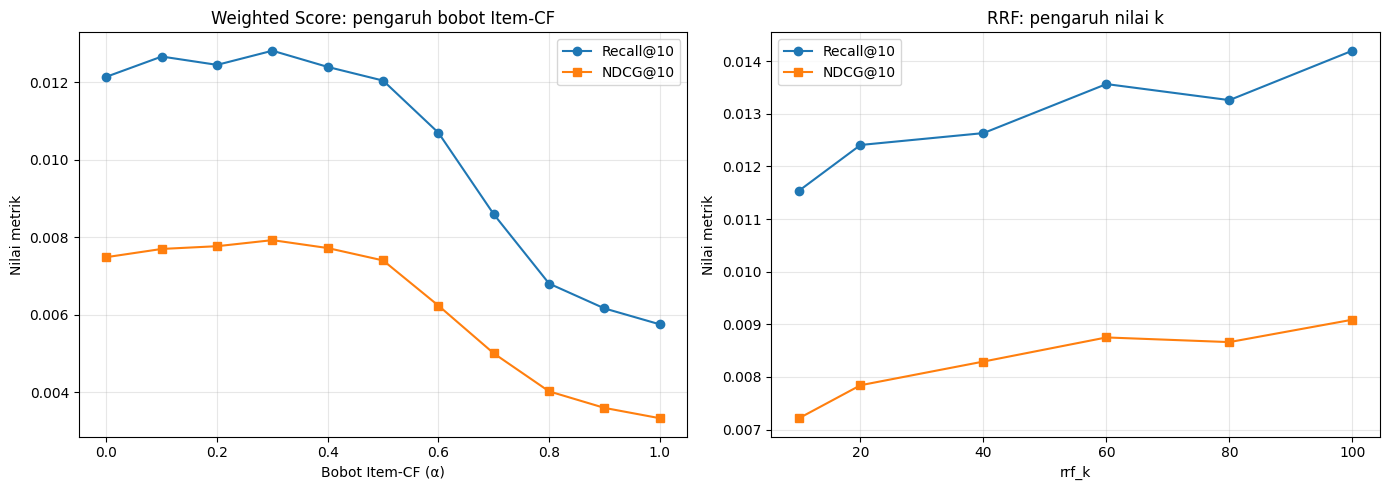

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(weighted_results.sort_values("bobot_item_cf")["bobot_item_cf"],
             weighted_results.sort_values("bobot_item_cf")["recall@10"],
             marker="o", label="Recall@10")
axes[0].plot(weighted_results.sort_values("bobot_item_cf")["bobot_item_cf"],
             weighted_results.sort_values("bobot_item_cf")["ndcg@10"],
             marker="s", label="NDCG@10")
axes[0].set_title("Weighted Score: pengaruh bobot Item-CF")
axes[0].set_xlabel("Bobot Item-CF (α)")
axes[0].set_ylabel("Nilai metrik")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(rrf_results.sort_values("rrf_k")["rrf_k"],
             rrf_results.sort_values("rrf_k")["recall@10"],
             marker="o", label="Recall@10")
axes[1].plot(rrf_results.sort_values("rrf_k")["rrf_k"],
             rrf_results.sort_values("rrf_k")["ndcg@10"],
             marker="s", label="NDCG@10")
axes[1].set_title("RRF: pengaruh nilai k")
axes[1].set_xlabel("rrf_k")
axes[1].set_ylabel("Nilai metrik")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Audit konsistensi rekomendasi

Pemeriksaan ini memastikan setiap model menghasilkan ranking untuk seluruh evaluable users, tidak memiliki item duplikat, hanya menggunakan candidate universe resmi, tidak merekomendasikan item yang sudah dilihat saat training, dan maksimal `TOP_N` item per pengguna.

In [8]:
def extract_item_ids(ranking):
    result = []
    for entry in ranking:
        if isinstance(entry, (tuple, list)):
            result.append(str(entry[0]))
        else:
            result.append(str(entry))
    return result

def audit_recommendations(recs_by_user, model_name, max_items=TOP_N):
    assert set(map(str, recs_by_user.keys())) == eval_user_set, (
        f"{model_name}: himpunan pengguna tidak sama dengan evaluable users."
    )
    for uid in eval_users:
        ranked = extract_item_ids(recs_by_user[uid])
        assert len(ranked) <= max_items, f"{model_name}: melebihi {max_items} item."
        assert len(ranked) == len(set(ranked)), f"{model_name}: ada item duplikat."
        assert set(ranked).issubset(candidate_set), f"{model_name}: item di luar candidate set."
        assert not (set(ranked) & seen_by_user.get(uid, set())), (
            f"{model_name}: merekomendasikan item yang sudah dilihat saat training."
        )
    return {"Model": model_name, "Status audit": "PASS", "Jumlah user": len(eval_users)}

audit_table = pd.DataFrame([
    audit_recommendations(pop_recs, "Popularity"),
    audit_recommendations(cf_recs, "Item-CF"),
    audit_recommendations(cbf_recs, "TF-IDF CBF"),
    audit_recommendations(best_weighted_recs, "Weighted Score"),
    audit_recommendations(best_rrf_recs, "RRF"),
])
display(audit_table)

,Model,Status audit,Jumlah user
0,Popularity,PASS,11659
1,Item-CF,PASS,11659
2,TF-IDF CBF,PASS,11659
3,Weighted Score,PASS,11659
4,RRF,PASS,11659


## 9. Interpretasi hasil otomatis

Interpretasi berikut dibuat dari hasil yang benar-benar dihitung saat notebook dijalankan. Perhatikan bahwa hybrid terbaik tidak otomatis berarti lebih baik daripada semua baseline pada kedua metrik.

In [9]:
rrf_recall = float(best_rrf_metrics["recall@10"])
rrf_ndcg = float(best_rrf_metrics["ndcg@10"])
weighted_recall = float(best_weighted_metrics["recall@10"])
weighted_ndcg = float(best_weighted_metrics["ndcg@10"])
pop_metrics = evaluate_ranking(pop_recs, relevant, eval_users, k=K)
pop_recall = float(pop_metrics["recall@10"])
pop_ndcg = float(pop_metrics["ndcg@10"])

print(f"Weighted Score terbaik: CF={best_cf_weight:.1f}, "
      f"Recall@10={weighted_recall:.6f}, NDCG@10={weighted_ndcg:.6f}")
print(f"RRF terbaik          : k={best_rrf_k}, "
      f"Recall@10={rrf_recall:.6f}, NDCG@10={rrf_ndcg:.6f}")

if rrf_recall > weighted_recall and rrf_ndcg > weighted_ndcg:
    print("\nRRF mengungguli Weighted Score pada Recall@10 dan NDCG@10.")
elif rrf_recall >= weighted_recall and rrf_ndcg >= weighted_ndcg:
    print("\nRRF setidaknya menyamai Weighted Score pada kedua metrik.")
else:
    print("\nRRF tidak mengungguli Weighted Score pada seluruh metrik.")

print("\nPerbandingan RRF dengan Popularity:")
print("Recall@10:", "lebih tinggi" if rrf_recall > pop_recall else "tidak lebih tinggi")
print("NDCG@10  :", "lebih tinggi" if rrf_ndcg > pop_ndcg else "tidak lebih tinggi")

Weighted Score terbaik: CF=0.3, Recall@10=0.012820, NDCG@10=0.007930
RRF terbaik          : k=100, Recall@10=0.014198, NDCG@10=0.009086

RRF mengungguli Weighted Score pada Recall@10 dan NDCG@10.

Perbandingan RRF dengan Popularity:
Recall@10: lebih tinggi
NDCG@10  : tidak lebih tinggi


## 10. Simpan hasil Task 3

Notebook menyimpan tabel konfigurasi, tabel perbandingan, audit, dan ringkasan parameter terbaik ke folder `outputs/task3/`.

In [10]:
weighted_results.to_csv(OUTPUT_DIR / "task3_weighted_score_results.csv", index=False)
rrf_results.to_csv(OUTPUT_DIR / "task3_rrf_results.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "task3_model_comparison.csv")
audit_table.to_csv(OUTPUT_DIR / "task3_recommendation_audit.csv", index=False)

summary_json = {
    "task": "CP3 - Task 3 Experiment Evaluation",
    "dataset": "Amazon Reviews 2023 - Musical Instruments",
    "evaluation_split": "validation_warm",
    "uses_final_test": False,
    "train_interactions": int(len(train)),
    "validation_warm_interactions": int(len(validation)),
    "candidate_universe_size": int(len(candidate_set)),
    "evaluable_users": int(len(eval_users)),
    "positive_rating_threshold": POSITIVE_THRESHOLD,
    "metric_k": K,
    "component_top_k": 100,
    "recommendation_top_n": TOP_N,
    "fusion_output_top_n": FUSION_TOP_N,
    "cache_key": CACHE_KEY,
    "selection_rule": "Highest NDCG@10, Recall@10 as tie-breaker",
    "best_weighted_score": {
        "item_cf_weight": best_cf_weight,
        "tfidf_cbf_weight": round(1 - best_cf_weight, 1),
        "recall@10": weighted_recall,
        "ndcg@10": weighted_ndcg,
    },
    "best_rrf": {
        "rrf_k": best_rrf_k,
        "recall@10": rrf_recall,
        "ndcg@10": rrf_ndcg,
    },
    "popularity_baseline": {
        "recall@10": pop_recall,
        "ndcg@10": pop_ndcg,
    },
    "recommendation_audit": "PASS",
}

(OUTPUT_DIR / "task3_summary.json").write_text(
    json.dumps(summary_json, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("Task 3 selesai. Artefak disimpan:")
for path in sorted(OUTPUT_DIR.glob("task3_*")):
    print("-", path.relative_to(PROJECT_ROOT))

Task 3 selesai. Artefak disimpan:
- outputs\task3\task3_model_comparison.csv
- outputs\task3\task3_recommendation_audit.csv
- outputs\task3\task3_rrf_results.csv
- outputs\task3\task3_summary.json
- outputs\task3\task3_weighted_score_results.csv
